In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score

#Load DATA

In [82]:
df=pd.read_csv(r"C:\Users\m_hossam\OneDrive\Desktop\data\alzheimers_disease_data.csv")
df.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


#PRE... Processing

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

|  # | Column Name               | المعنى بالعربي               | الشرح                                                                      | نوع البيانات        |
| -: | ------------------------- | ---------------------------- | -------------------------------------------------------------------------- | ------------------- |
|  1 | `PatientID`               | رقم المريض                   | رقم مميز لتحديد كل مريض، وغالبًا لا نستخدمه كـ Feature في الموديل.         | Integer             |
|  2 | `Age`                     | العمر                        | عمر المريض بالسنوات، ويمكن استخدامه لدراسة العلاقة بين العمر والمرض.       | Numerical           |
|  3 | `Gender`                  | النوع                        | النوع المسجل للمريض، ومُرمّز بأرقام تحتاج إلى تفسير.                       | Categorical         |
|  4 | `Ethnicity`               | الأصل العرقي                 | يمثل المجموعة العرقية للمريض، وكل رقم قد يشير إلى فئة مختلفة.              | Categorical         |
|  5 | `EducationLevel`          | المستوى التعليمي             | يمثل مستوى تعليم المريض، وقد تكون القيم مرتبة حسب المستوى التعليمي.        | Ordinal Categorical |
|  6 | `BMI`                     | مؤشر كتلة الجسم              | مؤشر يعتمد على الوزن والطول لتقدير تناسب الوزن مع الطول.                   | Numerical           |
|  7 | `Smoking`                 | التدخين                      | يمثل حالة التدخين لدى المريض، وغالبًا يُرمّز بقيم مثل 0 و1.                | Binary Categorical  |
|  8 | `AlcoholConsumption`      | استهلاك الكحول               | يمثل مستوى أو كمية استهلاك الكحول حسب تعريف الداتا.                        | Numerical           |
|  9 | `PhysicalActivity`        | النشاط البدني                | يمثل مستوى النشاط البدني للمريض أو مقدار ممارسته.                          | Numerical           |
| 10 | `DietQuality`             | جودة النظام الغذائي          | مؤشر يعبّر عن جودة النظام الغذائي للمريض.                                  | Numerical           |
| 11 | `SleepQuality`            | جودة النوم                   | مؤشر يعبّر عن جودة النوم وفقًا للمقياس المستخدم في الداتا.                 | Numerical           |
| 12 | `FamilyHistoryAlzheimers` | التاريخ العائلي لألزهايمر    | يوضح ما إذا كان لدى المريض تاريخ عائلي للمرض.                              | Binary Categorical  |
| 13 | `CardiovascularDisease`   | أمراض القلب والأوعية الدموية | يوضح وجود أو عدم وجود أمراض القلب والأوعية الدموية.                        | Binary Categorical  |
| 14 | `Diabetes`                | مرض السكري                   | يوضح ما إذا كان المريض مصابًا بالسكري.                                     | Binary Categorical  |
| 15 | `Depression`              | الاكتئاب                     | يوضح وجود أو عدم وجود تاريخ مرضي للاكتئاب وفقًا لتعريف الداتا.             | Binary Categorical  |
| 16 | `HeadInjury`              | إصابة الرأس                  | يوضح ما إذا كان المريض لديه تاريخ سابق لإصابة في الرأس.                    | Binary Categorical  |
| 17 | `Hypertension`            | ارتفاع ضغط الدم              | يوضح ما إذا كان المريض مصابًا بارتفاع ضغط الدم.                            | Binary Categorical  |
| 18 | `SystolicBP`              | ضغط الدم الانقباضي           | الرقم الأعلى في قراءة ضغط الدم، ويمثل الضغط أثناء انقباض القلب.            | Numerical           |
| 19 | `DiastolicBP`             | ضغط الدم الانبساطي           | الرقم الأقل في قراءة ضغط الدم، ويمثل الضغط أثناء ارتخاء القلب بين النبضات. | Numerical           |
| 20 | `CholesterolTotal`        | الكوليسترول الكلي            | يقيس إجمالي الكوليسترول في الدم، وفقًا لوحدة القياس المستخدمة في الداتا.   | Numerical           |


In [84]:
df.columns.tolist()

['PatientID',
 'Age',
 'Gender',
 'Ethnicity',
 'EducationLevel',
 'BMI',
 'Smoking',
 'AlcoholConsumption',
 'PhysicalActivity',
 'DietQuality',
 'SleepQuality',
 'FamilyHistoryAlzheimers',
 'CardiovascularDisease',
 'Diabetes',
 'Depression',
 'HeadInjury',
 'Hypertension',
 'SystolicBP',
 'DiastolicBP',
 'CholesterolTotal',
 'CholesterolLDL',
 'CholesterolHDL',
 'CholesterolTriglycerides',
 'MMSE',
 'FunctionalAssessment',
 'MemoryComplaints',
 'BehavioralProblems',
 'ADL',
 'Confusion',
 'Disorientation',
 'PersonalityChanges',
 'DifficultyCompletingTasks',
 'Forgetfulness',
 'Diagnosis',
 'DoctorInCharge']

In [85]:
df.shape

(2149, 35)

In [86]:
df.describe()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
count,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,...,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000
mean,5825.000000,74.908795,0.506282,0.697534,1.286645,27.655697,0.288506,10.039442,4.920202,4.993138,...,5.080055,0.208004,0.156817,4.982958,0.205212,0.158213,0.150768,0.158678,0.301536,0.353653
std,620.507185,8.990221,0.500077,0.996128,0.904527,7.217438,0.453173,5.757910,2.857191,2.909055,...,2.892743,0.405974,0.363713,2.949775,0.403950,0.365026,0.357906,0.365461,0.459032,0.478214
min,4751.000000,60.000000,0.000000,0.000000,0.000000,15.008851,0.000000,0.002003,0.003616,0.009385,...,0.000460,0.000000,0.000000,0.001288,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5288.000000,67.000000,0.000000,0.000000,1.000000,21.611408,0.000000,5.139810,2.570626,2.458455,...,2.566281,0.000000,0.000000,2.342836,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5825.000000,75.000000,1.000000,0.000000,1.000000,27.823924,0.000000,9.934412,4.766424,5.076087,...,5.094439,0.000000,0.000000,5.038973,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,6362.000000,83.000000,1.000000,1.000000,2.000000,33.869778,1.000000,15.157931,7.427899,7.558625,...,7.546981,0.000000,0.000000,7.581490,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,6899.000000,90.000000,1.000000,3.000000,3.000000,39.992767,1.000000,19.989293,9.987429,9.998346,...,9.996467,1.000000,1.000000,9.999747,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [87]:
df["Diagnosis"].value_counts()

Diagnosis
0    1389
1     760
Name: count, dtype: int64

In [88]:
df.isna().sum()

PatientID                    0
Age                          0
Gender                       0
Ethnicity                    0
EducationLevel               0
BMI                          0
Smoking                      0
AlcoholConsumption           0
PhysicalActivity             0
DietQuality                  0
SleepQuality                 0
FamilyHistoryAlzheimers      0
CardiovascularDisease        0
Diabetes                     0
Depression                   0
HeadInjury                   0
Hypertension                 0
SystolicBP                   0
DiastolicBP                  0
CholesterolTotal             0
CholesterolLDL               0
CholesterolHDL               0
CholesterolTriglycerides     0
MMSE                         0
FunctionalAssessment         0
MemoryComplaints             0
BehavioralProblems           0
ADL                          0
Confusion                    0
Disorientation               0
PersonalityChanges           0
DifficultyCompletingTasks    0
Forgetfu

In [89]:
df.duplicated().value_counts()

False    2149
Name: count, dtype: int64

In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

In [91]:
df["DoctorInCharge"].value_counts()

DoctorInCharge
XXXConfid    2149
Name: count, dtype: int64

In [92]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PatientID,2149.0,NaN,NaN,NaN,5825.0,620.507185,4751.0,5288.0,5825.0,6362.0,6899.0
Age,2149.0,NaN,NaN,NaN,74.908795,8.990221,60.0,67.0,75.0,83.0,90.0
Gender,2149.0,NaN,NaN,NaN,0.506282,0.500077,0.0,0.0,1.0,1.0,1.0
Ethnicity,2149.0,NaN,NaN,NaN,0.697534,0.996128,0.0,0.0,0.0,1.0,3.0
EducationLevel,2149.0,NaN,NaN,NaN,1.286645,0.904527,0.0,1.0,1.0,2.0,3.0
BMI,2149.0,NaN,NaN,NaN,27.655697,7.217438,15.008851,21.611408,27.823924,33.869778,39.992767
Smoking,2149.0,NaN,NaN,NaN,0.288506,0.453173,0.0,0.0,0.0,1.0,1.0
AlcoholConsumption,2149.0,NaN,NaN,NaN,10.039442,5.75791,0.002003,5.13981,9.934412,15.157931,19.989293
PhysicalActivity,2149.0,NaN,NaN,NaN,4.920202,2.857191,0.003616,2.570626,4.766424,7.427899,9.987429
DietQuality,2149.0,NaN,NaN,NaN,4.993138,2.909055,0.009385,2.458455,5.076087,7.558625,9.998346


In [93]:
df.describe(include="object")

,DoctorInCharge
count,2149
unique,1
top,XXXConfid
freq,2149


In [94]:
df.columns.tolist()

['PatientID',
 'Age',
 'Gender',
 'Ethnicity',
 'EducationLevel',
 'BMI',
 'Smoking',
 'AlcoholConsumption',
 'PhysicalActivity',
 'DietQuality',
 'SleepQuality',
 'FamilyHistoryAlzheimers',
 'CardiovascularDisease',
 'Diabetes',
 'Depression',
 'HeadInjury',
 'Hypertension',
 'SystolicBP',
 'DiastolicBP',
 'CholesterolTotal',
 'CholesterolLDL',
 'CholesterolHDL',
 'CholesterolTriglycerides',
 'MMSE',
 'FunctionalAssessment',
 'MemoryComplaints',
 'BehavioralProblems',
 'ADL',
 'Confusion',
 'Disorientation',
 'PersonalityChanges',
 'DifficultyCompletingTasks',
 'Forgetfulness',
 'Diagnosis',
 'DoctorInCharge']

In [95]:
df = df.drop(columns=["PatientID", "DoctorInCharge"])

In [96]:
df.columns.value_counts().sum()

np.int64(33)

#Visulazation

In [97]:
sns.set_theme(style="whitegrid")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (2149, 33)


,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
0,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,9.025679,...,6.518877,0,0,1.725883,0,0,0,1,0,0
1,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,7.151293,...,7.118696,0,0,2.592424,0,0,0,0,1,0
2,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,9.673574,...,5.895077,0,0,7.119548,0,1,0,1,0,0
3,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,8.392554,...,8.965106,0,1,6.481226,0,0,0,0,0,0
4,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,5.597238,...,6.045039,0,0,0.014691,0,0,1,1,0,0


Diagnosis
0    1389
1     760
Name: count, dtype: int64

Percentages:
Diagnosis
0    64.634714
1    35.365286
Name: proportion, dtype: float64


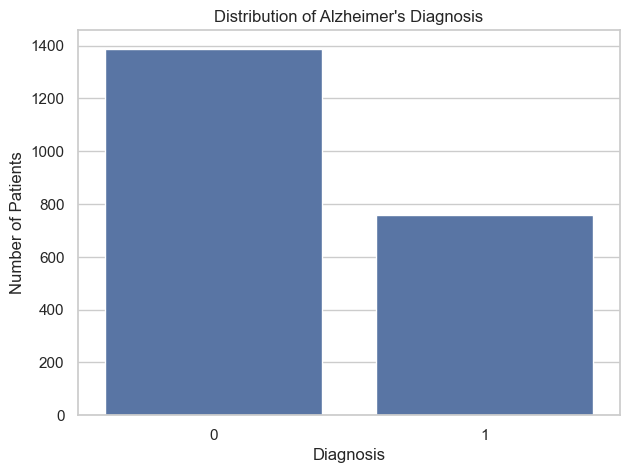

In [98]:
print(df["Diagnosis"].value_counts())
print("\nPercentages:")
print(df["Diagnosis"].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Diagnosis")

plt.title("Distribution of Alzheimer's Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")

plt.show()

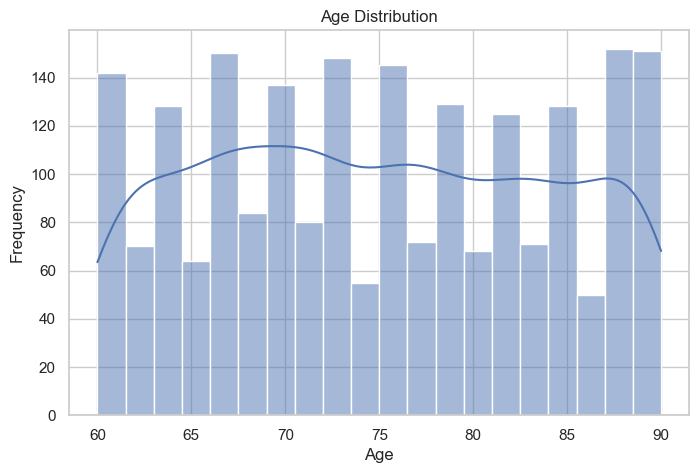

In [99]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

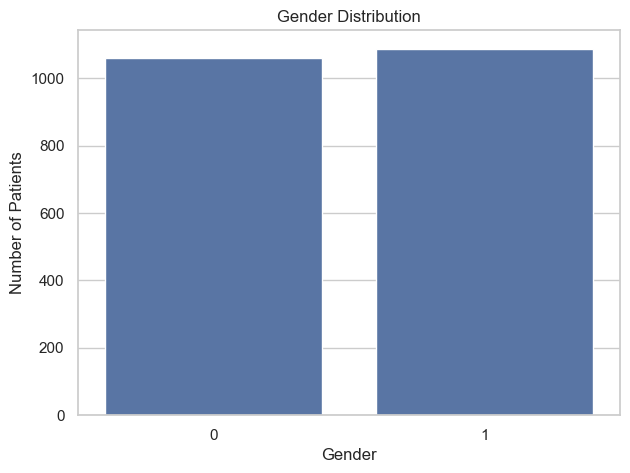

In [100]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

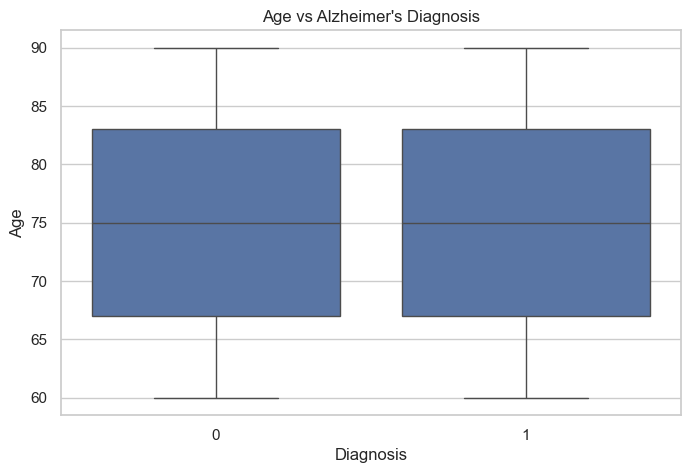

In [101]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Diagnosis", y="Age")

plt.title("Age vs Alzheimer's Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Age")

plt.show()

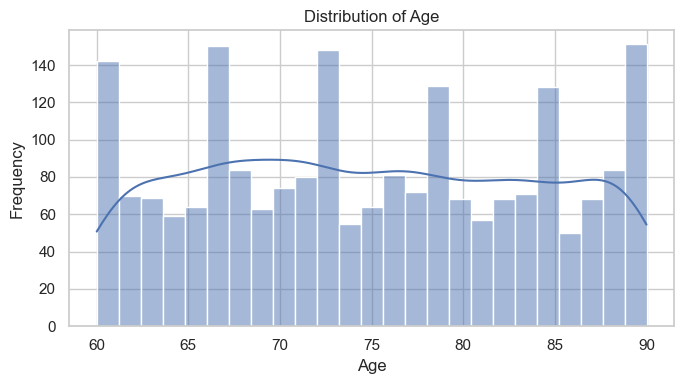

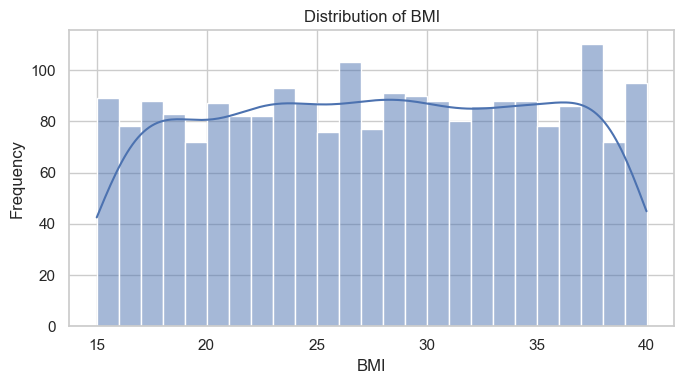

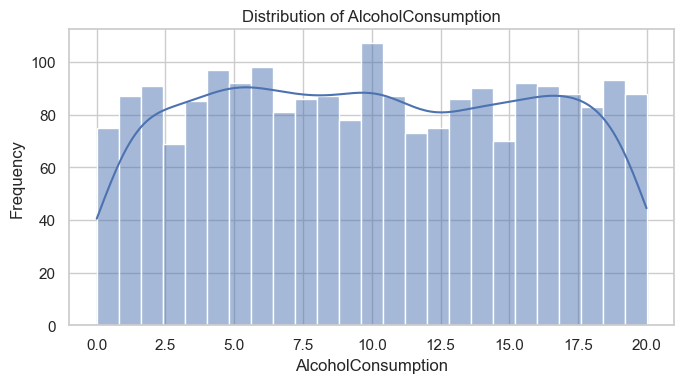

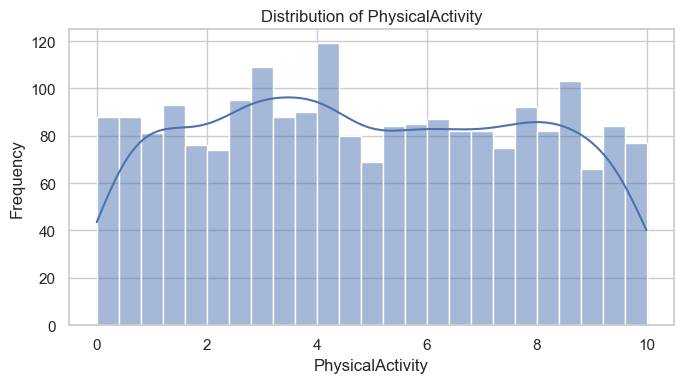

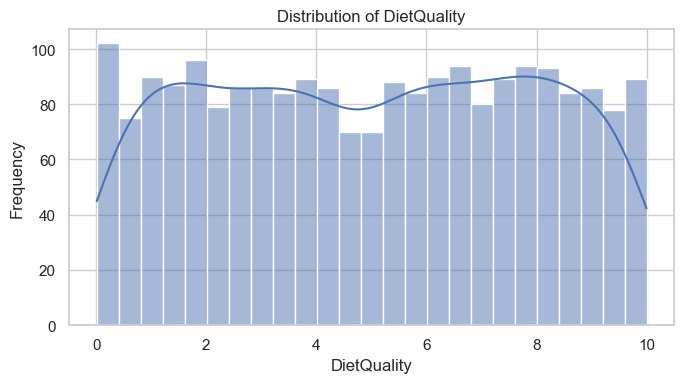

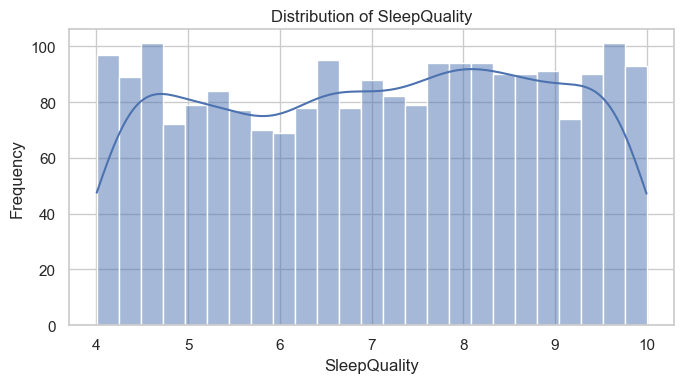

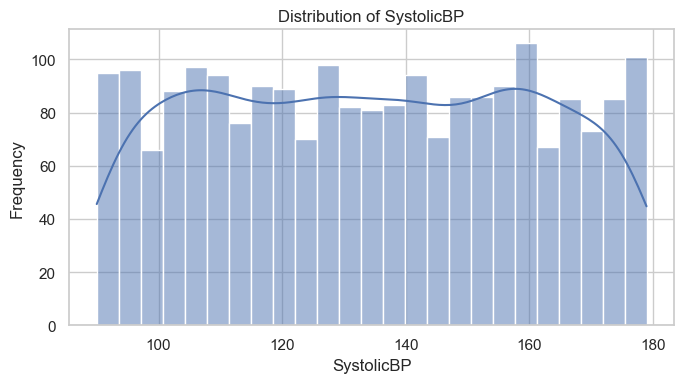

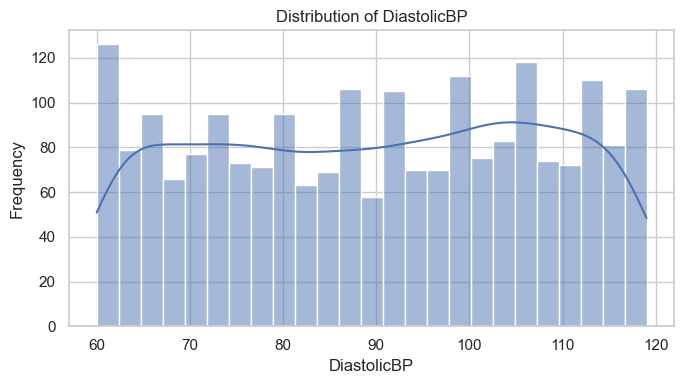

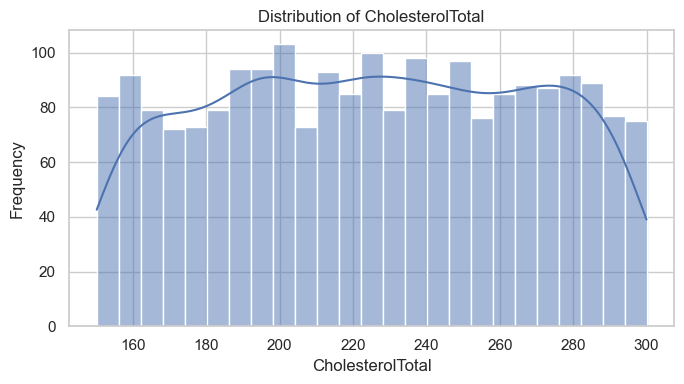

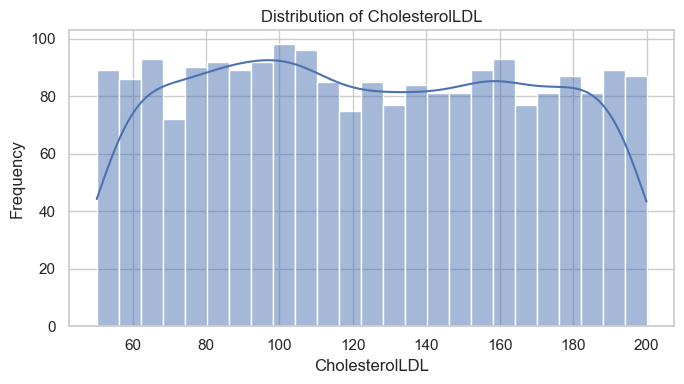

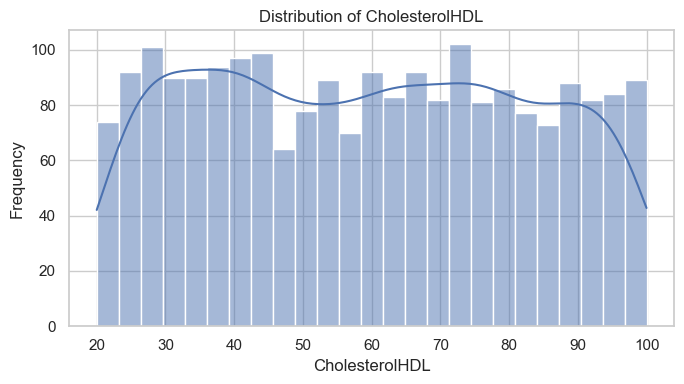

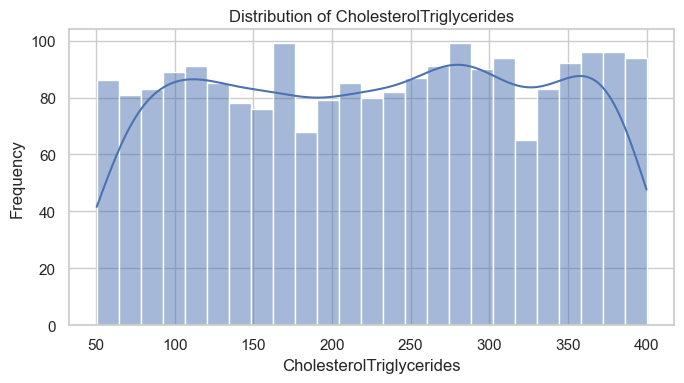

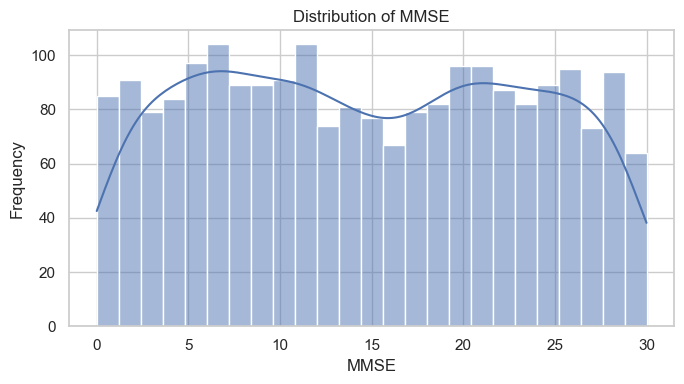

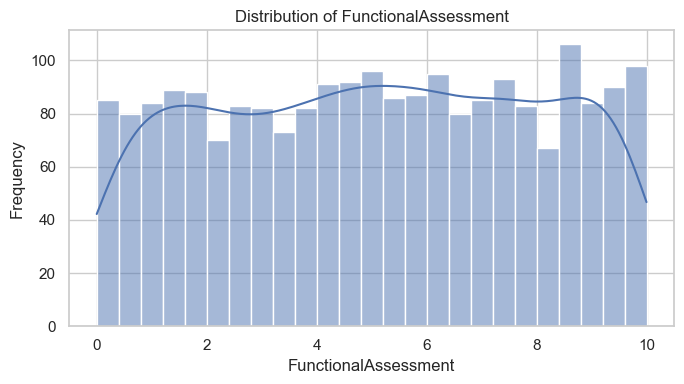

In [102]:
numerical_cols = [
    "Age",
    "BMI",
    "AlcoholConsumption",
    "PhysicalActivity",
    "DietQuality",
    "SleepQuality",
    "SystolicBP",
    "DiastolicBP",
    "CholesterolTotal",
    "CholesterolLDL",
    "CholesterolHDL",
    "CholesterolTriglycerides",
    "MMSE",
    "FunctionalAssessment"
]

for col in numerical_cols:
    plt.figure(figsize=(7, 4))

    sns.histplot(data=df, x=col, bins=25, kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

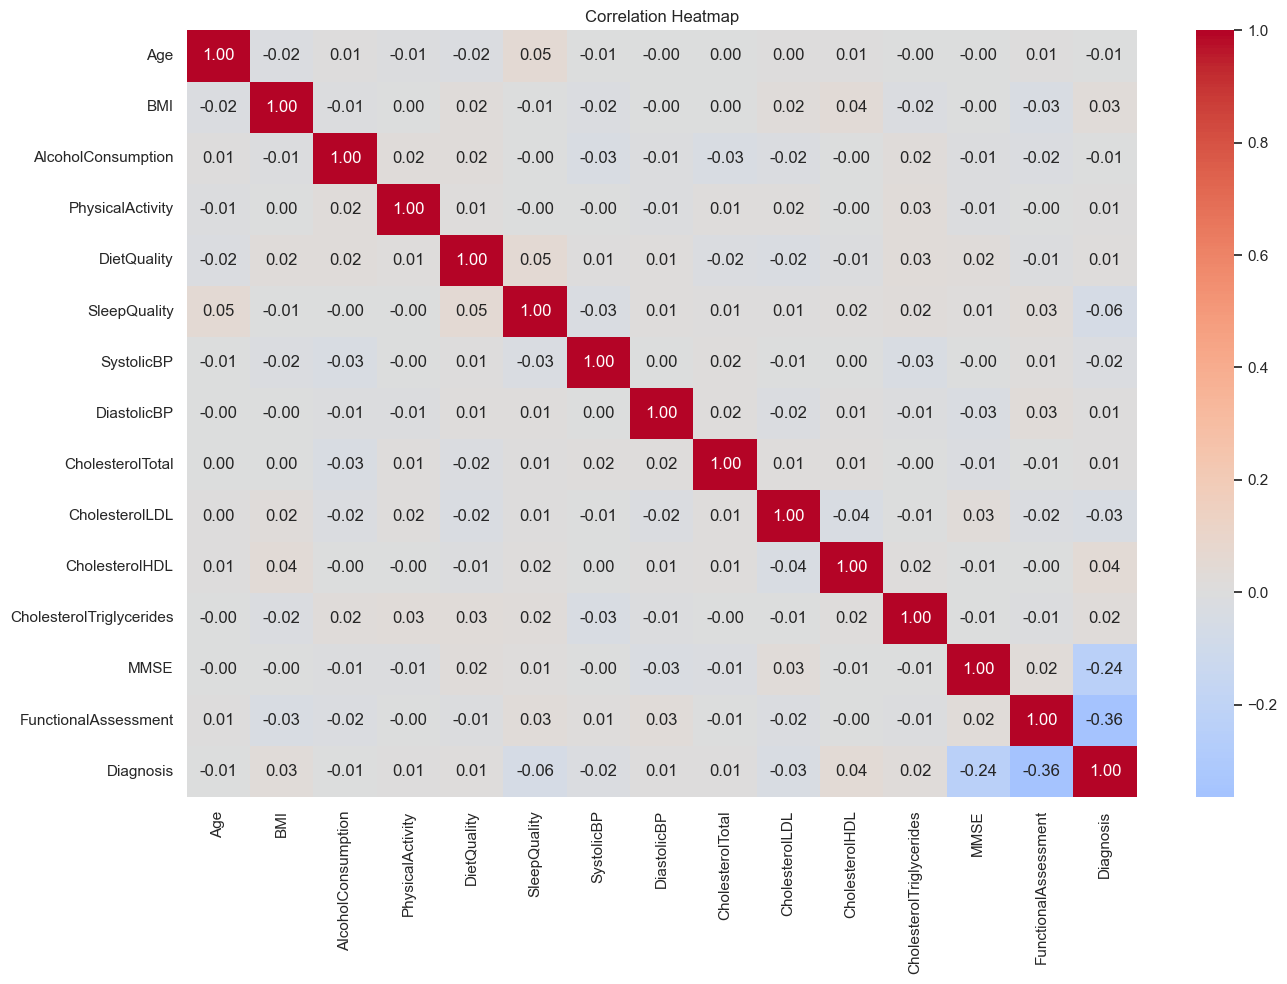

In [103]:
corr_cols = numerical_cols + ["Diagnosis"]

corr_matrix = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

#outliers if exist

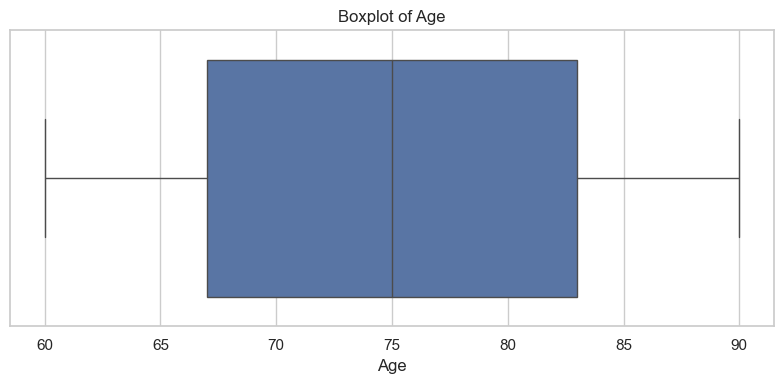

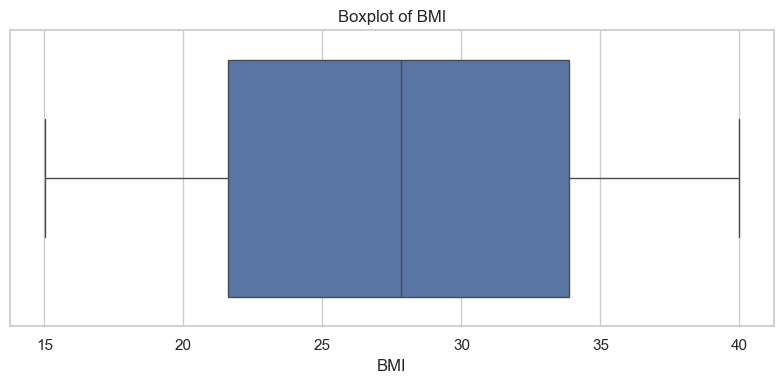

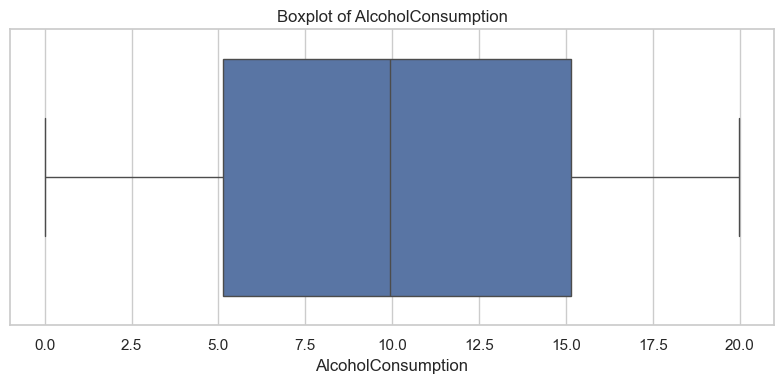

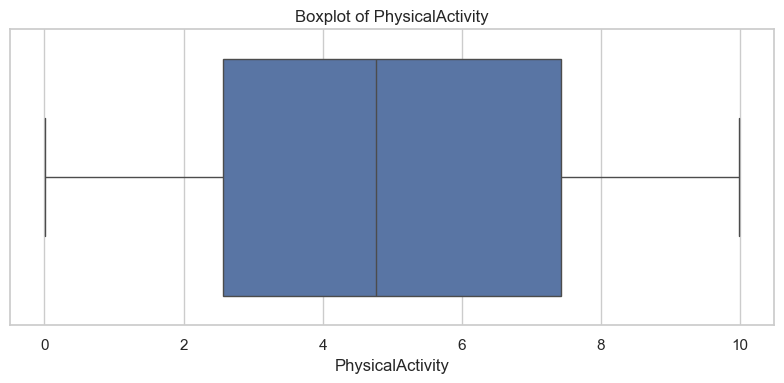

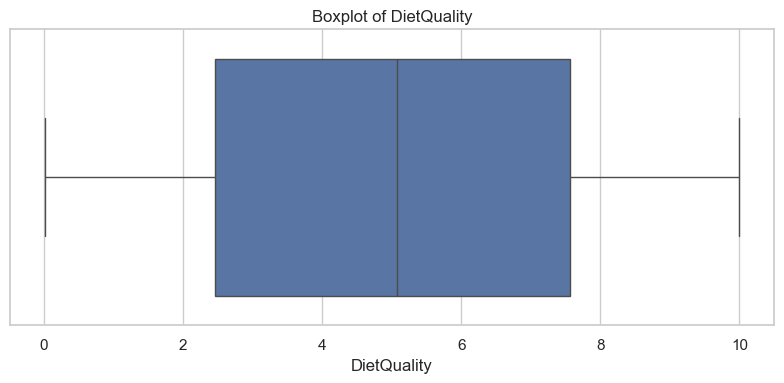

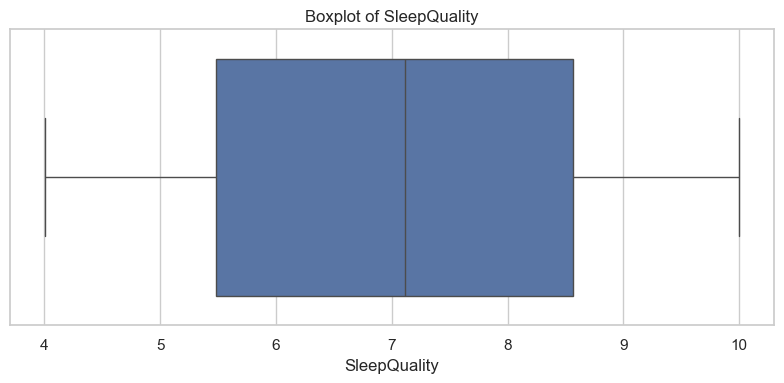

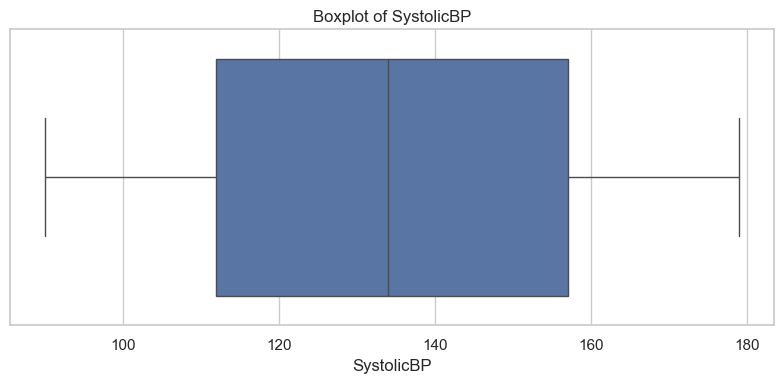

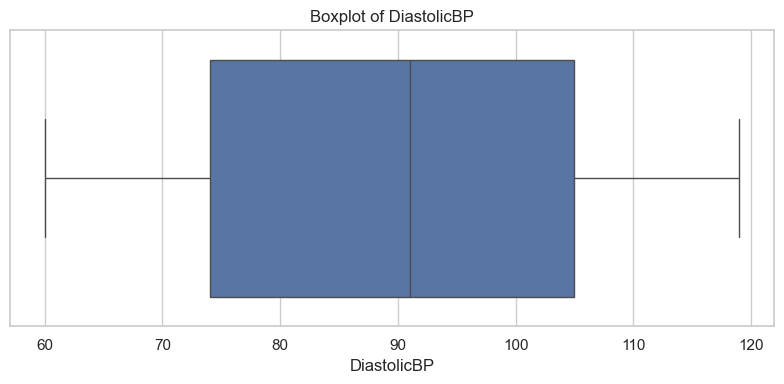

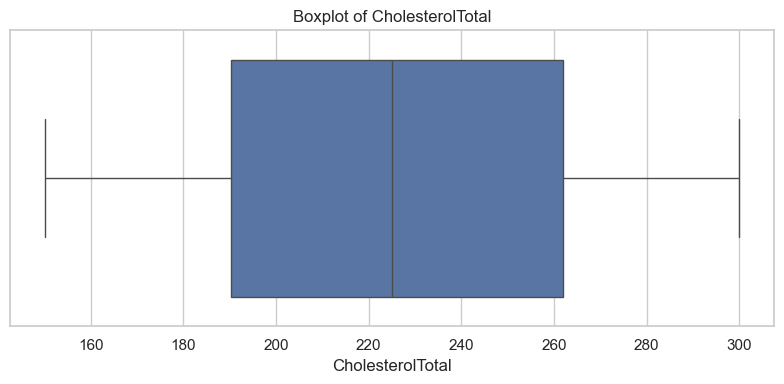

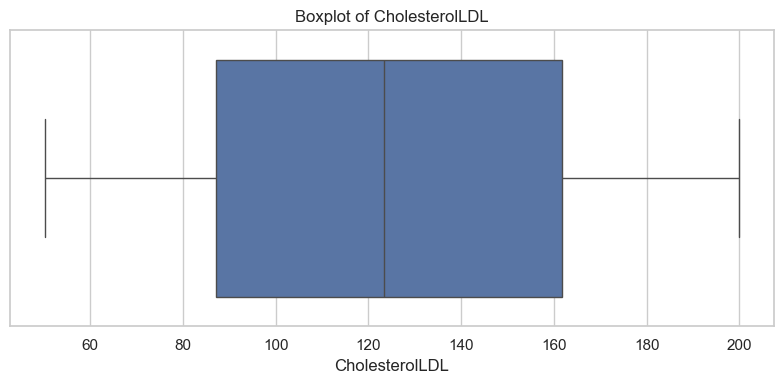

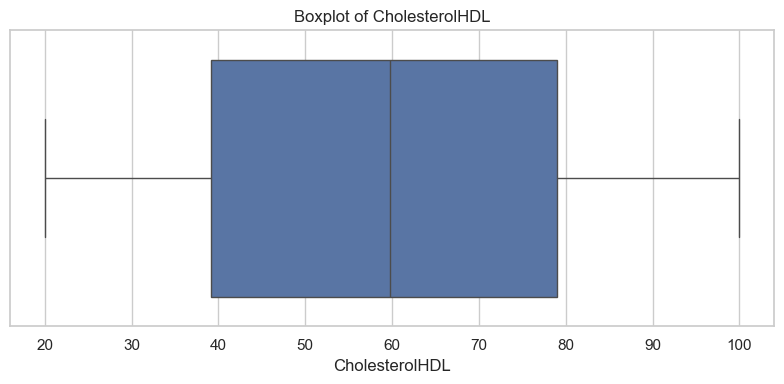

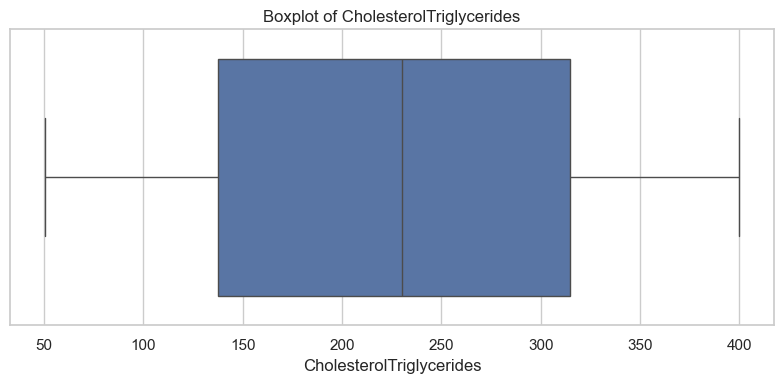

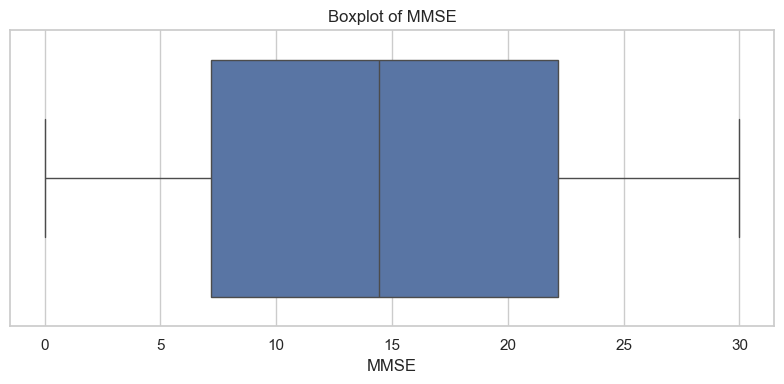

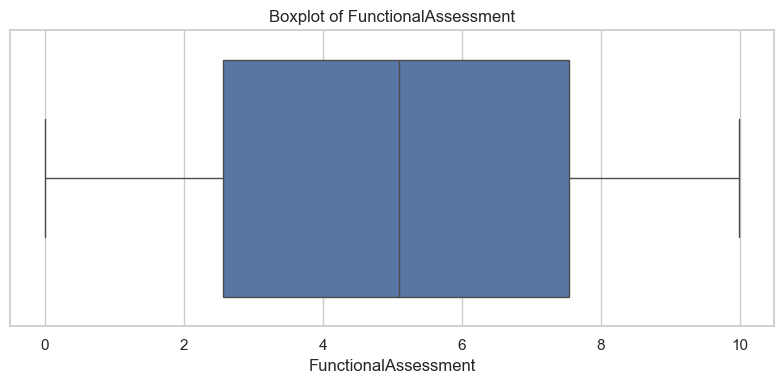

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [105]:
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Column": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Count": len(outliers),
        "Outliers Percentage": (
            len(outliers) / len(df) * 100
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        "Outliers Percentage",
        ascending=False
    ).round(2)
)

,Column,Lower Bound,Upper Bound,Outliers Count,Outliers Percentage
0,Age,43.00,107.00,0,0.0
1,BMI,3.22,52.26,0,0.0
2,AlcoholConsumption,-9.89,30.19,0,0.0
3,PhysicalActivity,-4.72,14.71,0,0.0
4,DietQuality,-5.19,15.21,0,0.0
5,SleepQuality,0.86,13.18,0,0.0
6,SystolicBP,44.50,224.50,0,0.0
7,DiastolicBP,27.50,151.50,0,0.0
8,CholesterolTotal,82.58,369.70,0,0.0
9,CholesterolLDL,-24.61,273.54,0,0.0


In [106]:
print(df["Diagnosis"].value_counts(dropna=False))

Diagnosis
0    1389
1     760
Name: count, dtype: int64


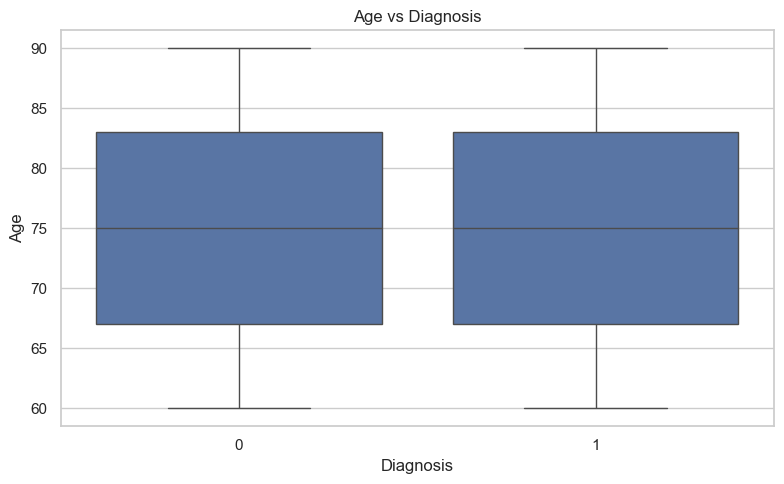

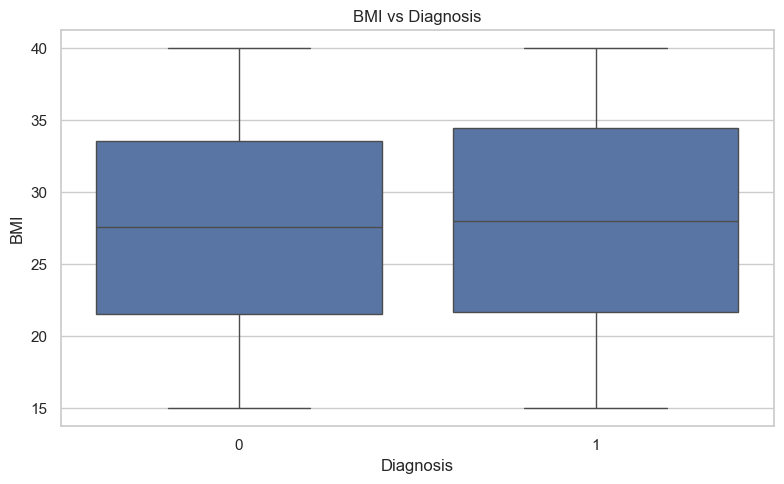

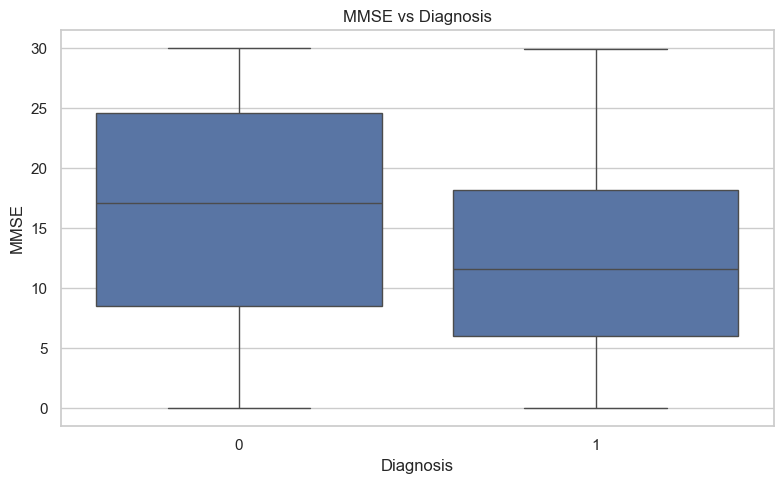

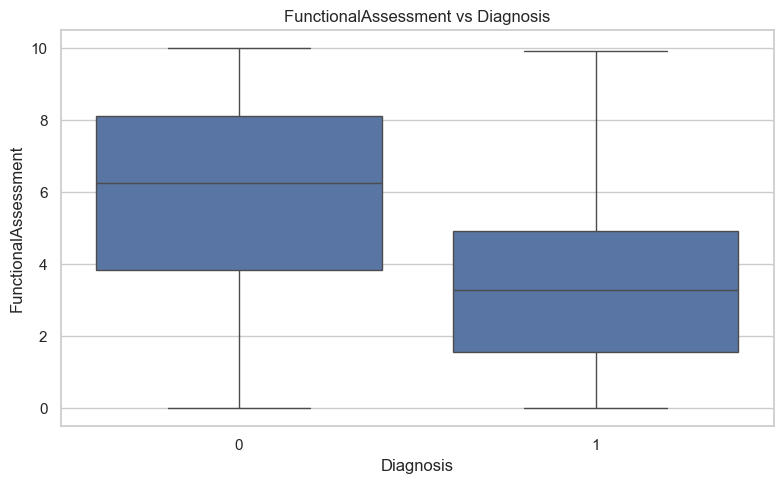

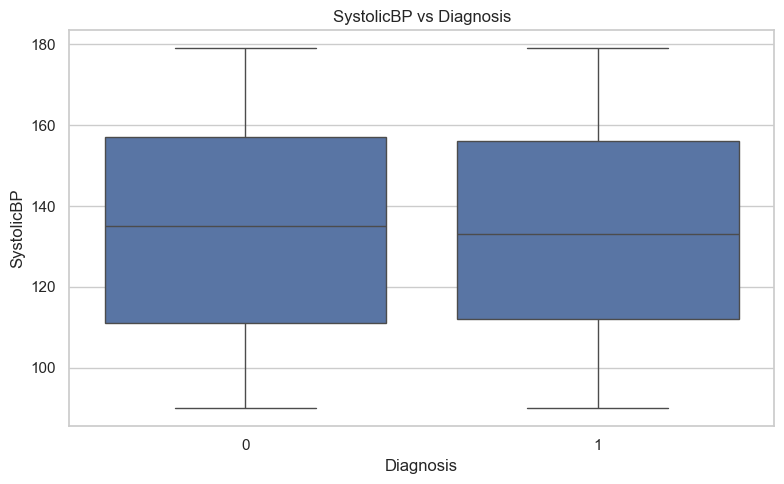

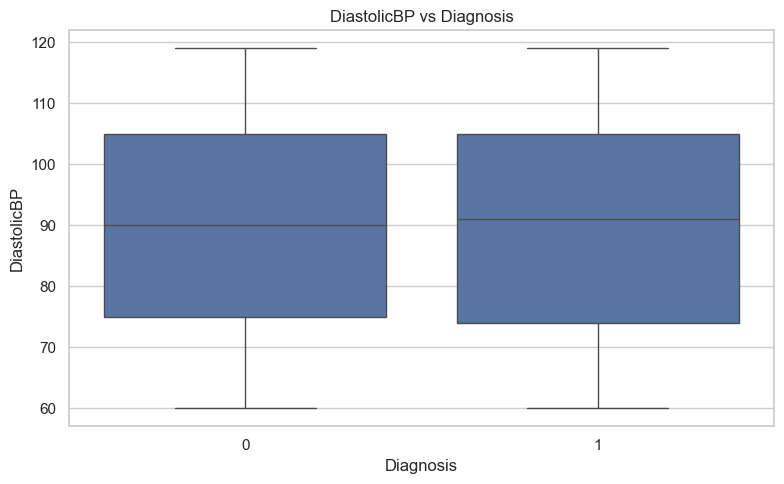

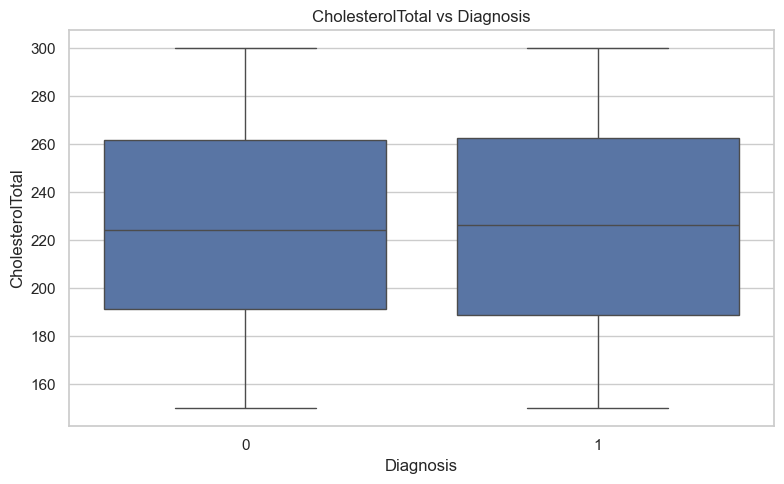

In [107]:
comparison_cols = [
    "Age",
    "BMI",
    "MMSE",
    "FunctionalAssessment",
    "SystolicBP",
    "DiastolicBP",
    "CholesterolTotal"
]

for col in comparison_cols:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="Diagnosis",
        y=col
    )

    plt.title(f"{col} vs Diagnosis")
    plt.xlabel("Diagnosis")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

In [108]:
group_comparison = df.groupby("Diagnosis")[comparison_cols].agg(
    ["mean", "median", "std"]
)

display(group_comparison.round(2))

Age                 BMI                MMSE               \
            mean median   std   mean median   std   mean median   std   
Diagnosis                                                               
0          74.95   75.0  8.90  27.52  27.56  7.17  16.27  17.15  8.93   
1          74.84   75.0  9.15  27.91  28.00  7.30  11.99  11.57  7.23   

          FunctionalAssessment  ...       SystolicBP                \
                          mean  ...   std       mean median    std   
Diagnosis                       ...                                  
0                         5.86  ...  2.76     134.56  135.0  25.95   
1                         3.65  ...  2.57     133.72  133.0  25.96   

          DiastolicBP               CholesterolTotal                 
                 mean median    std             mean  median    std  
Diagnosis                                                            
0               89.78   90.0  17.67           225.00  224.45  42.20  
1               89.97   91.0  17.46           225.57  226.45  43.19  

[2 rows x 21 columns]

In [109]:
binary_cols = [
    "Smoking",
    "FamilyHistoryAlzheimers",
    "CardiovascularDisease",
    "Diabetes",
    "Depression",
    "HeadInjury",
    "Hypertension",
    "MemoryComplaints",
    "BehavioralProblems",
    "PersonalityChanges",
    "DifficultyCompletingTasks",
    "Forgetfulness"
]

for col in binary_cols:

    if col not in df.columns:
        continue

    rates = df.groupby("Diagnosis")[col].mean() * 100

    print(f"\n{col}")
    display(rates.rename("Percentage of value 1").round(2))


Smoking


Diagnosis
0    29.01
1    28.55
Name: Percentage of value 1, dtype: float64


FamilyHistoryAlzheimers


Diagnosis
0    26.28
1    23.29
Name: Percentage of value 1, dtype: float64


CardiovascularDisease


...

Diagnosis
0    15.62
1    14.08
Name: Percentage of value 1, dtype: float64


DifficultyCompletingTasks


Diagnosis
0    15.62
1    16.32
Name: Percentage of value 1, dtype: float64


Forgetfulness


Diagnosis
0    30.17
1    30.13
Name: Percentage of value 1, dtype: float64

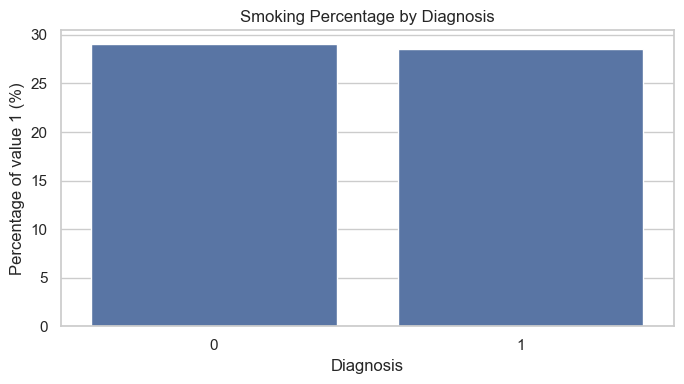

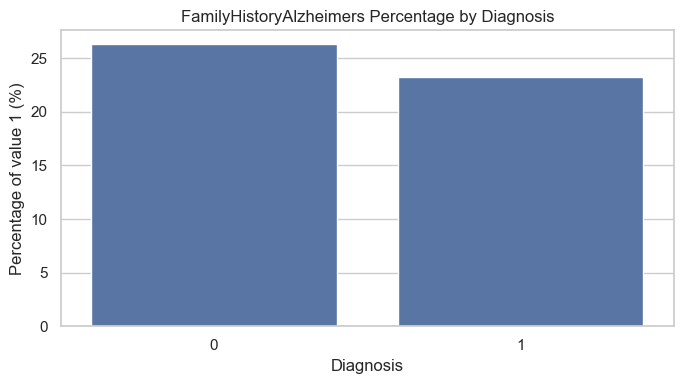

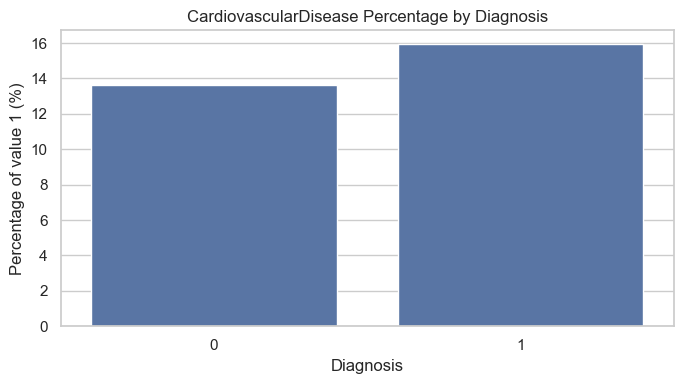

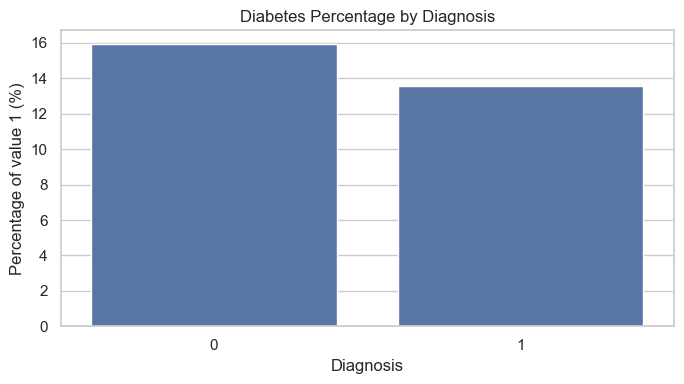

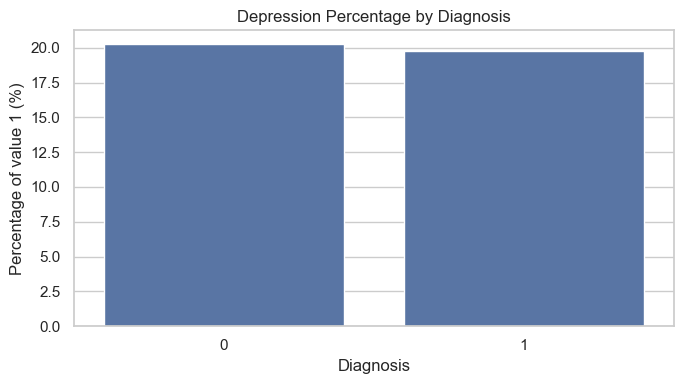

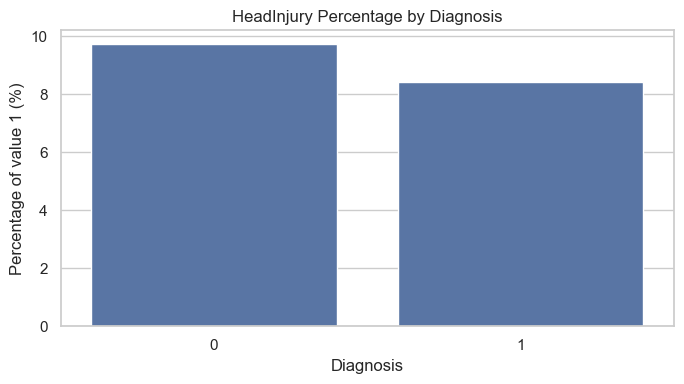

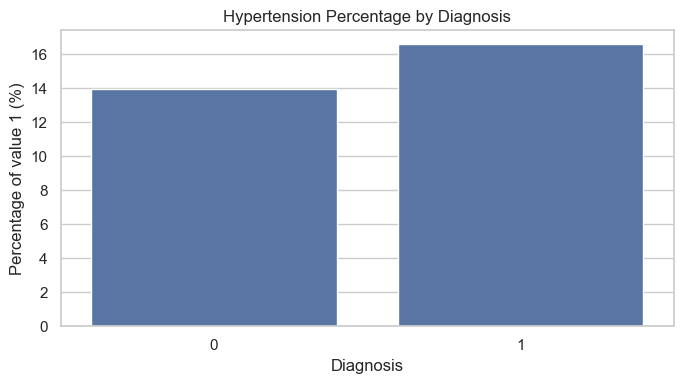

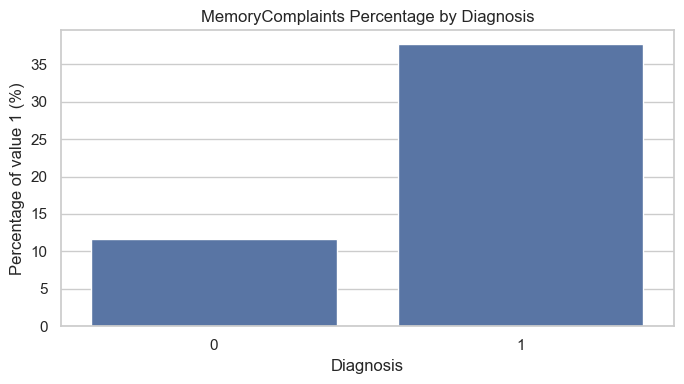

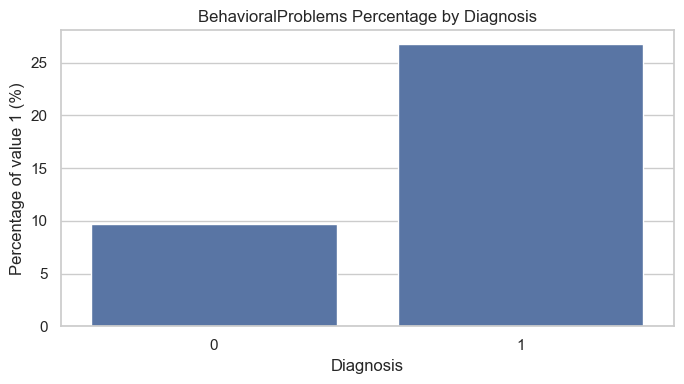

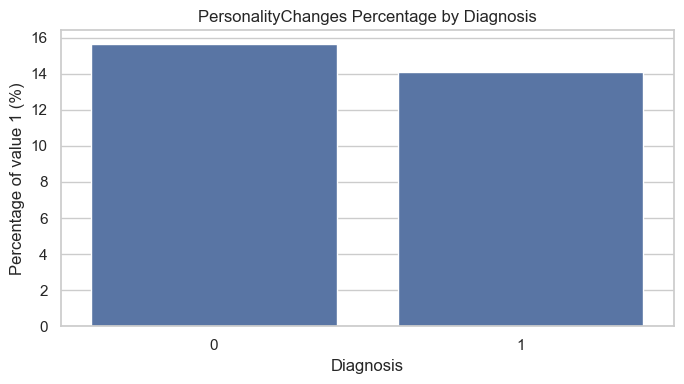

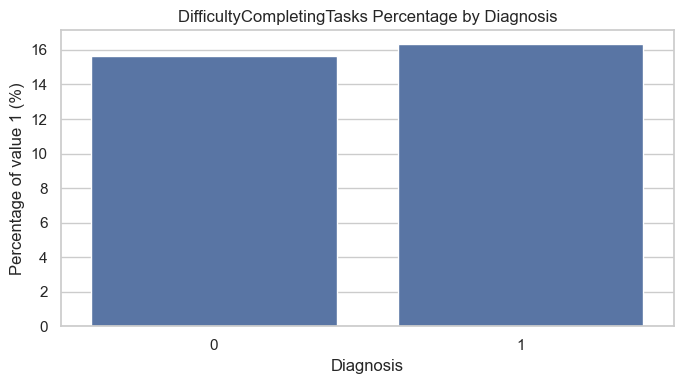

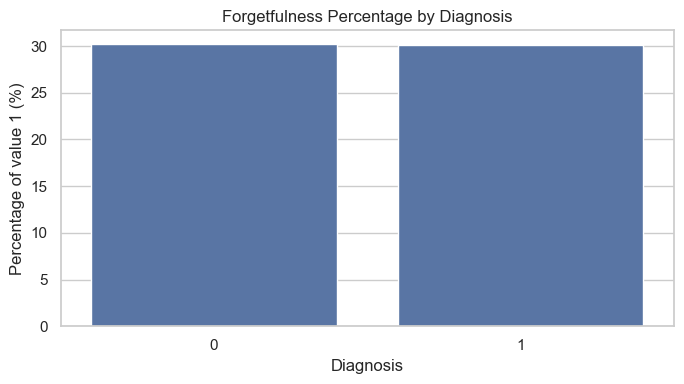

In [110]:
for col in binary_cols:

    if col not in df.columns:
        continue

    rates = (
        df.groupby("Diagnosis")[col]
        .mean()
        .mul(100)
        .reset_index(name="Percentage")
    )

    plt.figure(figsize=(7, 4))

    sns.barplot(
        data=rates,
        x="Diagnosis",
        y="Percentage"
    )

    plt.title(f"{col} Percentage by Diagnosis")
    plt.xlabel("Diagnosis")
    plt.ylabel("Percentage of value 1 (%)")

    plt.tight_layout()
    plt.show()

In [111]:
candidate_leakage_cols = [
    "MMSE",
    "FunctionalAssessment",
    "MemoryComplaints",
    "BehavioralProblems",
    "PersonalityChanges",
    "DifficultyCompletingTasks",
    "Forgetfulness"
]

for col in candidate_leakage_cols:

    if col not in df.columns:
        continue

    print(f"\nColumn: {col}")
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isna().sum())

    print(
        df.groupby("Diagnosis")[col]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )


Column: MMSE
Unique values: 2149
Missing values: 0
           count   mean  median   std
Diagnosis                            
0           1389  16.27   17.15  8.93
1            760  11.99   11.57  7.23

Column: FunctionalAssessment
Unique values: 2149
Missing values: 0
           count  mean  median   std
Diagnosis                           
0           1389  5.86    6.24  2.76
1            760  3.65    3.30  2.57

Column: MemoryComplaints
Unique values: 2
Missing values: 0
           count  mean  median   std
Diagnosis                           
0           1389  0.12     0.0  0.32
1            760  0.38     0.0  0.48

Column: BehavioralProblems
Unique values: 2
Missing values: 0
           count  mean  median   std
Diagnosis                           
0           1389  0.10     0.0  0.30
1            760  0.27     0.0  0.44

Column: PersonalityChanges
Unique values: 2
Missing values: 0
           count  mean  median   std
Diagnosis                           
0           1389  0.16 

In [112]:
binary_cols = [
    "Smoking",
    "FamilyHistoryAlzheimers",
    "CardiovascularDisease",
    "Diabetes",
    "Depression",
    "HeadInjury",
    "Hypertension",
    "MemoryComplaints",
    "BehavioralProblems",
    "PersonalityChanges",
    "DifficultyCompletingTasks",
    "Forgetfulness"
]

for col in binary_cols:
    if col in df.columns:
        print(f"\nColumn: {col}")

        result = df.groupby("Diagnosis")[col].agg(
            ["count", "mean"]
        )

        result["percentage_1"] = result["mean"] * 100

        display(result.round(2))


Column: Smoking


,count,mean,percentage_1
Diagnosis,,,
0,1389,0.29,29.01
1,760,0.29,28.55



Column: FamilyHistoryAlzheimers


,count,mean,percentage_1
Diagnosis,,,
0,1389,0.26,26.28
1,760,0.23,23.29



Column: CardiovascularDisease


...

,count,mean,percentage_1
Diagnosis,,,
0,1389,0.16,15.62
1,760,0.14,14.08



Column: DifficultyCompletingTasks


,count,mean,percentage_1
Diagnosis,,,
0,1389,0.16,15.62
1,760,0.16,16.32



Column: Forgetfulness


,count,mean,percentage_1
Diagnosis,,,
0,1389,0.3,30.17
1,760,0.3,30.13


In [113]:
X = df.drop(columns=["Diagnosis"])


y = df["Diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2149, 32)
y shape: (2149,)


In [114]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (1504, 32) (1504,)
Validation: (322, 32) (322,)
Testing: (323, 32) (323,)


In [115]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

def make_scaled_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

In [116]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

models = {
    "Logistic Regression": make_scaled_pipeline(
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "KNN": make_scaled_pipeline(
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            random_state=42,
            max_depth=10
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SVM": make_scaled_pipeline(
        SVC(probability=True, random_state=42)
    ),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=42))
    ])
}

In [117]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []
trained_models = {}

for name, model in models.items():

    # Train
    model.fit(X_train, y_train)

    # Predict validation labels
    y_pred = model.predict(X_val)

    # Predict probability of class 1
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_val)[:, 1]
    else:
        y_prob = None

    # Evaluate
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_val, y_prob)
            if y_prob is not None else None
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
  Gradient Boosting    0.9410     0.9524  0.8772    0.9132   0.9348
      Random Forest    0.9379     0.9796  0.8421    0.9057   0.9317
      Decision Tree    0.9006     0.8868  0.8246    0.8545   0.8822
Logistic Regression    0.8478     0.8155  0.7368    0.7742   0.8887
                SVM    0.8478     0.8283  0.7193    0.7700   0.8976
                KNN    0.7360     0.6883  0.4649    0.5550   0.7738


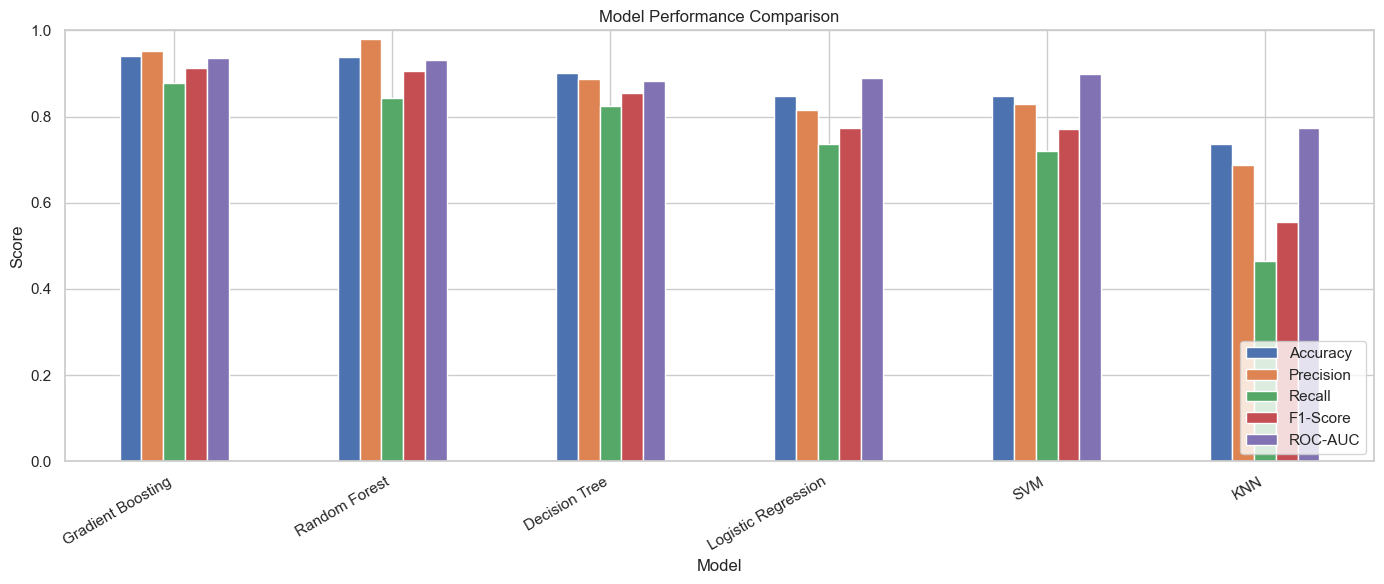

In [118]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [119]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: Gradient Boosting


Final Test Results
----------------------------------------
              precision    recall  f1-score   support

 Diagnosis 0       0.97      0.93      0.95       209
 Diagnosis 1       0.89      0.95      0.92       114

    accuracy                           0.94       323
   macro avg       0.93      0.94      0.93       323
weighted avg       0.94      0.94      0.94       323



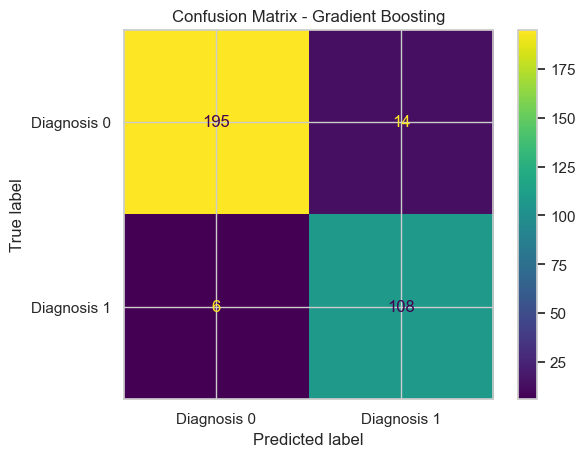

In [120]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_test_pred = best_model.predict(X_test)

print("Final Test Results")
print("-" * 40)

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Diagnosis 0", "Diagnosis 1"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Diagnosis 0", "Diagnosis 1"]
)

disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [121]:
import joblib

joblib.dump(best_model, "best_alzheimer_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [122]:
loaded_model = joblib.load("best_alzheimer_model.joblib")

new_predictions = loaded_model.predict(X_test)

print(new_predictions[:10])

[0 0 1 0 0 0 1 1 1 1]
